In [1]:
import warnings
warnings.filterwarnings('ignore')

import sys,os
from copy import copy
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

import numpy as np
import pandas as pd

import scanpy as sc
import anndata
mpl.rcParams['figure.dpi'] = 50
mpl.rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(facecolor=(0, 0, 0, 0), dpi=50, dpi_save=600)

sns.set_style({'axes.grid': False})


In [2]:
project_dir = '/home/xuquan/projects/pdac'
sc.settings.figdir = f'{project_dir}/figures/'


In [3]:
gns = copy(mpl.cm.Blues)
gns.set_under("lightgray")

plate_level_all0 = pd.read_csv(f"{project_dir}/db/pdac_color.txt",
                               sep='\t', header=None, index_col=0)
plate_level_all = plate_level_all0.to_dict()[1]
plate_level_all['nan'] = 'lightgray'
plate_level_all['na'] = 'lightgray'



In [4]:

adata = sc.read_h5ad(f"{project_dir}/pdac_atlas/all/pdac_scpoli_reannot_clear.h5ad")


In [5]:
for ct in adata.obs.wu_level_1.unique():
    if str(ct)!='nan':
        match_cts = adata[adata.obs.wu_level_1==ct].obs.level_1_late.value_counts().index[0]
        plate_level_all[ct] = plate_level_all[match_cts]

for ct in adata.obs.wu_level_2.unique():
    if str(ct)!='nan':
        match_cts = adata[adata.obs.wu_level_2==ct].obs.level_1_late.value_counts().index[0]
        plate_level_all[ct] = plate_level_all[match_cts]
        
for ct in adata.obs.ch_level_1.unique():
    if str(ct)!='nan':
        match_cts = adata[adata.obs.ch_level_1==ct].obs.level_1_late.value_counts().index[0]
        plate_level_all[ct] = plate_level_all[match_cts]

for ct in adata.obs.ch_level_2.unique():
    if str(ct)!='nan':
        match_cts = adata[adata.obs.ch_level_2==ct].obs.level_1_late.value_counts().index[0]
        plate_level_all[ct] = plate_level_all[match_cts]

plate_level_all['Acinar'] = plate_level_all['acinar cells']
plate_level_all['B cell'] = plate_level_all['B/plasma']
plate_level_all['Plasma'] = plate_level_all['B/plasma']
plate_level_all['Stellate'] = plate_level_all['stellate/pericyte like']
plate_level_all['Normal Epithelial'] = plate_level_all['ductal cells']
plate_level_all['Malignant - Basal'] = plate_level_all['basal like']
plate_level_all['Malignant - Classical'] = plate_level_all['classical epithelial']
plate_level_all['pancreatic acinar cell'] = plate_level_all['acinar cells']
plate_level_all['pancreatic ductal cell'] = plate_level_all['ductal cells']
plate_level_all['pancreatic stellate cell'] = plate_level_all['stellate/pericyte like']
plate_level_all['iCAF'] = plate_level_all['inflammatory CAF (iCAF)']
plate_level_all['myCAF'] = plate_level_all['myofibroblastic CAF (myCAF)']


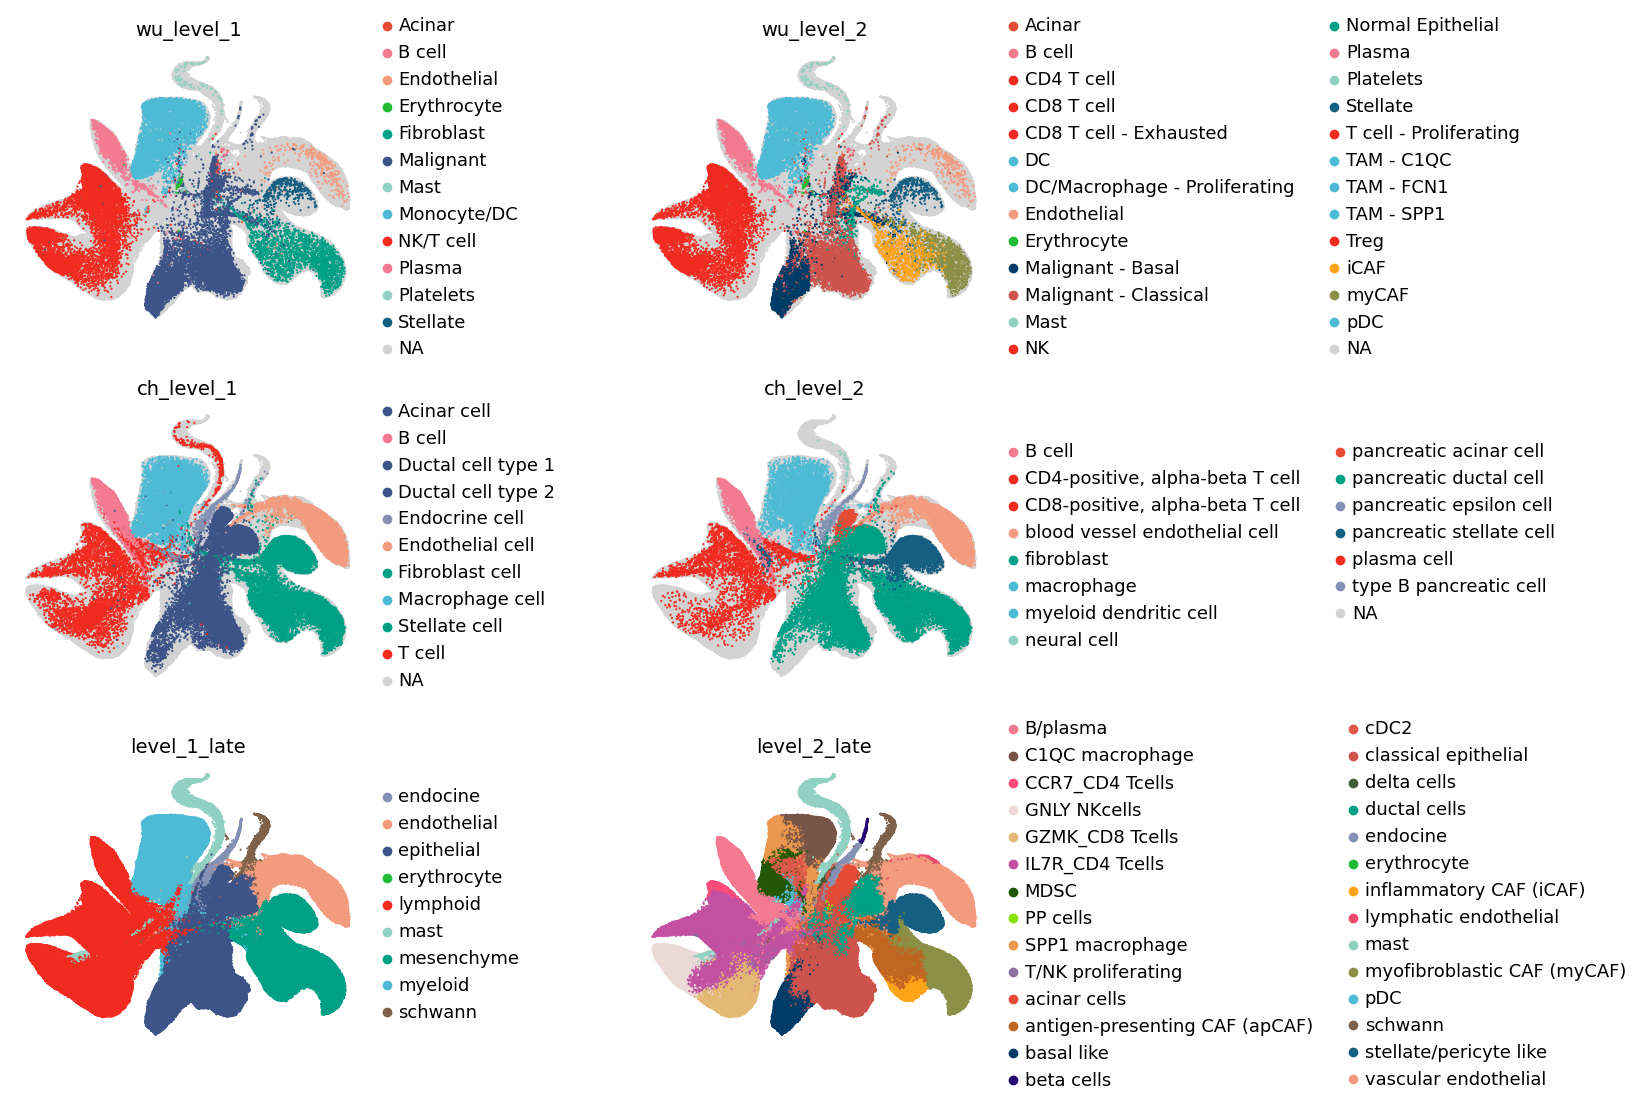

In [6]:
sc.pl.umap(adata, 
       color=['wu_level_1', 'wu_level_2', 'ch_level_1', 'ch_level_2', 'level_1_late', 'level_2_late'], 
       wspace=0.6, size=10, ncols=2, frameon=False, palette=plate_level_all)

In [7]:
wu_ann = adata.obs[['wu_level_1', 'wu_level_2', 'level_1_late', 'level_2_late']]
wu_ann = wu_ann[~wu_ann.wu_level_1.isna()]

ch_ann = adata.obs[['ch_level_1', 'ch_level_2', 'level_1_late', 'level_2_late']]
ch_ann = ch_ann[~ch_ann.ch_level_1.isna()]


def get_pect4plot(df, x, y):
    ct = pd.crosstab(df[y], df[x])
    ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
    cost = -ct_pct.values  # negative because we want max
    row_ind, col_ind = linear_sum_assignment(cost)
    ct_pct_opt = ct_pct.iloc[row_ind, col_ind]
    return ct_pct_opt

ct_pct_wu2 = get_pect4plot(wu_ann, 'level_2_late', 'wu_level_2')
ct_pct_ch2 = get_pect4plot(ch_ann, 'level_2_late', 'ch_level_2')

ct_pct_wu1 = get_pect4plot(wu_ann, 'level_1_late', 'wu_level_1')
ct_pct_ch1 = get_pect4plot(ch_ann, 'level_1_late', 'ch_level_1')


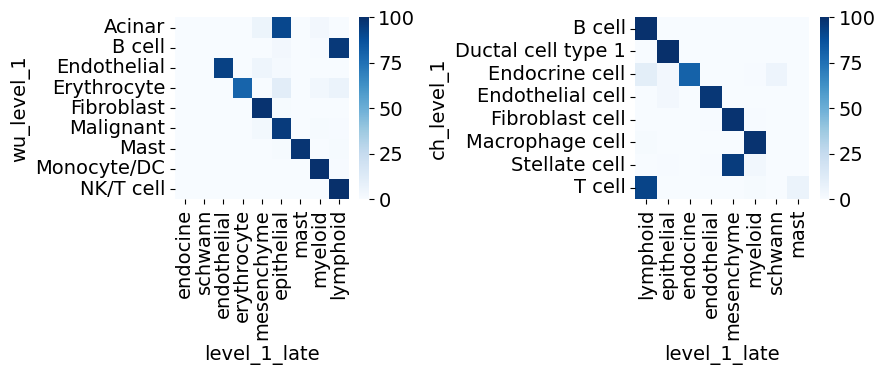

In [21]:

fig, axs = plt.subplots(1, 2, figsize=(9, 4))

sns.heatmap(ct_pct_wu1,cmap="Blues", vmin=0, vmax=100, ax=axs[0])
sns.heatmap(ct_pct_ch1,cmap="Blues", vmin=0,vmax=100, ax=axs[1])
plt.tight_layout()

fig.savefig(f'{project_dir}/figures/atlas_annot_compare_level1.pdf', bbox_inches="tight")


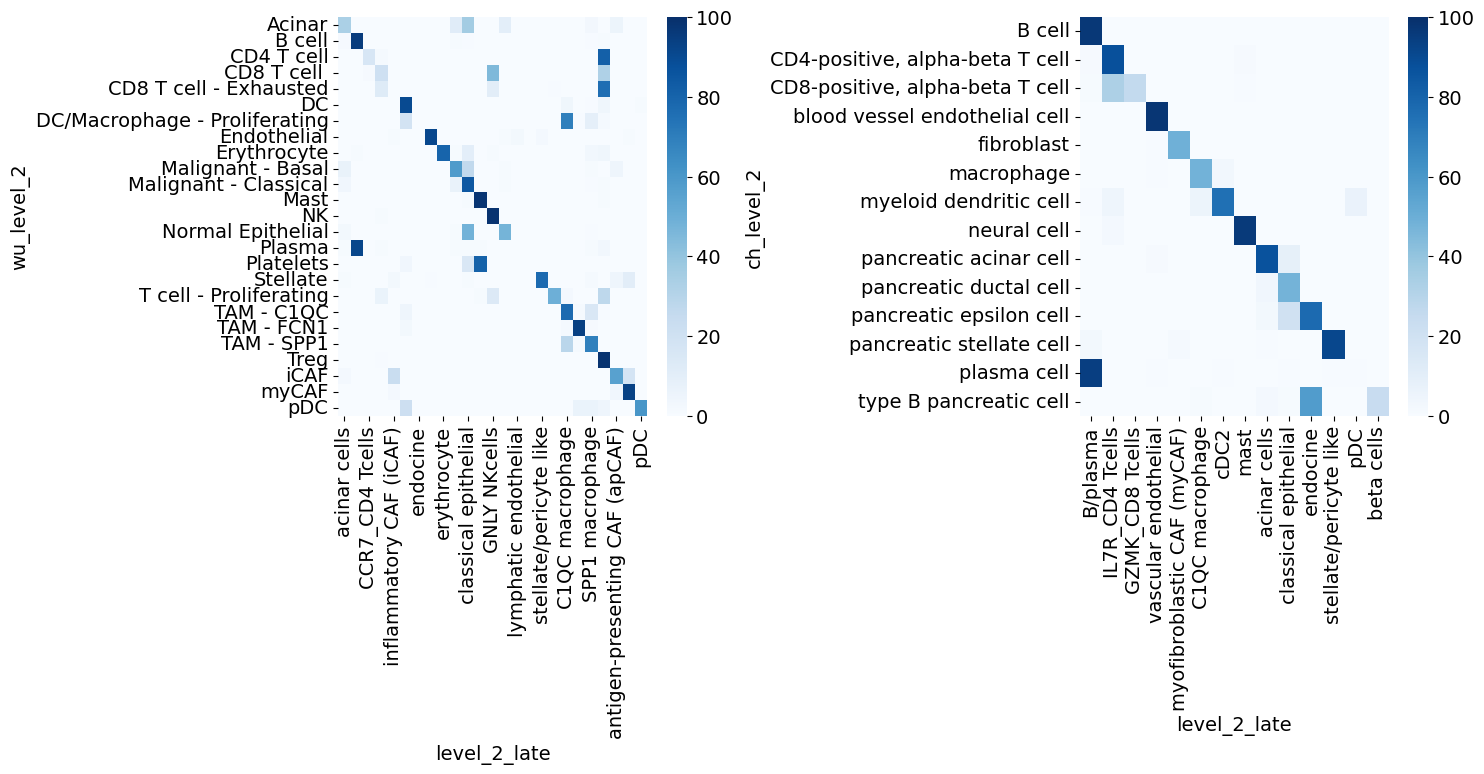

In [22]:

fig, axs = plt.subplots(1, 2, figsize=(15, 8))

sns.heatmap(ct_pct_wu2,cmap="Blues", vmin=0, vmax=100, ax=axs[0])
sns.heatmap(ct_pct_ch2,cmap="Blues", vmin=0,vmax=100, ax=axs[1])
plt.tight_layout()

fig.savefig(f'{project_dir}/figures/atlas_annot_compare_level2.pdf', bbox_inches="tight")
